In [ ]:
from google.colab import files
uploaded = files.upload()

Saving west.jpg to west (1).jpg
Saving south.jpg to south (1).jpg
Saving east.jpg to east (1).jpg
Saving north.jpg to north (1).jpg


In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter
from PIL import Image
import cv2
import matplotlib.pyplot as plt

def detect_vehicles_pure(image_path, sigma=6, min_area=800):

    # Step 1: grayscale using PIL (your original method)
    image = Image.open(image_path).convert('L')
    image_np = np.array(image)

    # Step 2: Gaussian blur (your original method)
    blurred = gaussian_filter(image_np, sigma=sigma)
    blurred = blurred.astype(np.uint8)

    # Step 3: FIXED threshold (important change)
    _, thresh = cv2.threshold(
        blurred, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Step 4: Morphology to remove noise
    kernel = np.ones((5,5), np.uint8)
    thresh = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel)

    # Step 5: contours
    contours, _ = cv2.findContours(
        thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    # Step 6: FILTER REAL VEHICLES ONLY
    vehicles = 0
    image_color = cv2.cvtColor(image_np, cv2.COLOR_GRAY2BGR)

    for c in contours:
        area = cv2.contourArea(c)
        if area > min_area:
            vehicles += 1
            cv2.drawContours(image_color, [c], -1, (0,255,0), 2)

    # Step 7: visualization (same style as your code)
    plt.figure(figsize=(12,6))

    plt.subplot(1,3,1)
    plt.title("Original")
    plt.imshow(image_np, cmap='gray')
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.title("Threshold")
    plt.imshow(thresh, cmap='gray')
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.title(f"Vehicles Detected: {vehicles}")
    plt.imshow(image_color)
    plt.axis('off')

    plt.show()

    return vehicles

In [ ]:
HEADWAY = 2.0
DISCHARGE_RATE = 1.0 / HEADWAY

phase_names = ["North", "East", "South", "West"]

def serve_cycle(counts, greens):
    new_counts = counts.copy()

    for i, g in enumerate(greens):
        can_depart = int(DISCHARGE_RATE * g)
        departed = min(new_counts[i], can_depart)
        new_counts[i] -= departed

    return new_counts

In [ ]:
lane_images = {
    "North": "north.jpg",
    "East": "east.jpg",
    "South": "south.jpg",
    "West": "west.jpg"
}

# counts = {}

# for lane, img in lane_images.items():
#     print(f"\nProcessing {lane}")
#     counts[lane] = detect_vehicles_pure(img, sigma=2, min_area=200)

# print("\nFINAL VEHICLE COUNTS:")
# print(counts)

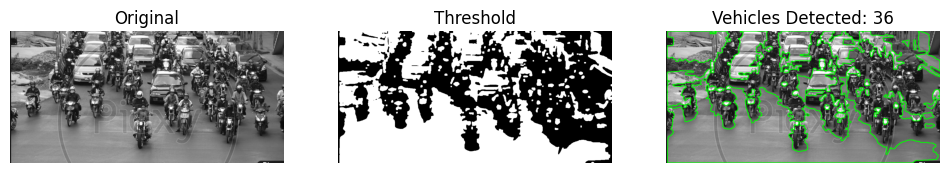

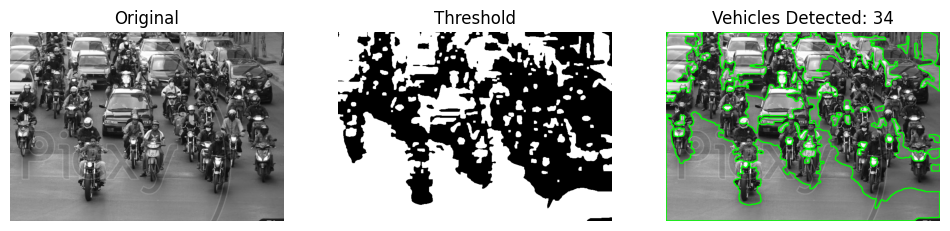

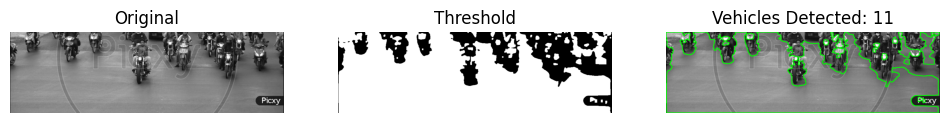

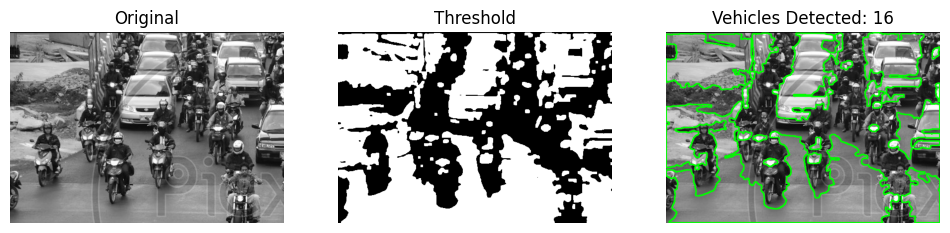


Initial Vehicle Counts:
North: 36
East: 34
South: 11
West: 16

===== Cycle 1 =====

Green Time Allocation:
North: 22.27 sec
East: 21.03 sec
South: 6.80 sec
West: 9.90 sec

Remaining Vehicles:
North: 25
East: 24
South: 8
West: 12

===== Cycle 2 =====

Green Time Allocation:
North: 21.74 sec
East: 20.87 sec
South: 6.96 sec
West: 10.43 sec

Remaining Vehicles:
North: 15
East: 14
South: 5
West: 7

===== Cycle 3 =====

Green Time Allocation:
North: 21.95 sec
East: 20.49 sec
South: 7.32 sec
West: 10.24 sec

Remaining Vehicles:
North: 5
East: 4
South: 2
West: 2

===== Cycle 4 =====

Green Time Allocation:
North: 23.08 sec
East: 18.46 sec
South: 9.23 sec
West: 9.23 sec

Remaining Vehicles:
North: 0
East: 0
South: 0
West: 0

🚀 All vehicles cleared. Traffic normalized.


In [ ]:
def run_until_cleared():

    # Step 1: Detect ONCE
    counts = []
    for lane in phase_names:
        c = detect_vehicles_pure(lane_images[lane], sigma=2, min_area=200)
        counts.append(c)

    print("\nInitial Vehicle Counts:")
    for i in range(4):
        print(f"{phase_names[i]}: {counts[i]}")

    cycle_num = 1

    # Step 2: Loop until all vehicles are gone
    while sum(counts) > 0:

        print(f"\n===== Cycle {cycle_num} =====")

        total = sum(counts)

        # Green time allocation
        if total == 0:
            greens = [10, 10, 10, 10]
        else:
            greens = [(c / total) * 60 for c in counts]

        print("\nGreen Time Allocation:")
        for i in range(4):
            print(f"{phase_names[i]}: {greens[i]:.2f} sec")

        # Serve vehicles
        counts = serve_cycle(counts, greens)

        print("\nRemaining Vehicles:")
        for i in range(4):
            print(f"{phase_names[i]}: {counts[i]}")

        cycle_num += 1

    print("\n🚀 All vehicles cleared. Traffic normalized.")

run_until_cleared()